## Calcul de la vitesse à partir d'un codeur incrémental

On suppose un système de contrôle de vitesse d'un moteur sur lequel un capteur incrémental est monté. Le capteur a une résolution de 500 stries.

Le système effectue le réglage à une période $T_s= 1[ms]$

Un timer permet de mesure le temps entre 2 transitions positives du signal A du capteur. Le timer mesure le temps à partir d'une horloge $f=1[MHz]$.

Un compteur compte les transitions des signaux A et B du capteur.

### Q1 Quelle est la précision relative en fonction de la vitesse de rotation pour chaque méthode

- Calculez l'expression de l'erreur
- Tracez un graphique avec les 2 courbes

### Q2 A quelle vitesse de rotation l'une des méthodes est avantageuse sur l'autre

- Quelle est la vitesse où l'erreur est la même ?
- Que se passe-t-il si la fréquence du compteur est de 100MHz ?

### Q3 Réflexion

- Quelles sont les sources d'erreur possibles
- Que se passe-t-il quand le moteur s'arrête




## Résolution

On définit les variables symboliques dont on a besoin

| Variable | Description |
|---|---|
| $p_1$ | valeur du compteur au temps $t_1$ |
| $p_2$ | valeur du compteur au temps $t_2$ |
| $T_s$ | période d'échantillonnage |
| $v_m$ | vitesse de rotation en tr/min |
| $R$ | résolution du codeur en stries |
| $f$ | fréquence de l'horloge du timer en Hz |

In [ ]:
import sympy as sp
import matplotlib.pyplot as plt

p1,p2,Ts,vm,R,f=sp.symbols("p1,p2,Ts,v_m,R,f")

# Calcul de la vitesse selon 2 méthodes

# 1. Méthode différence de compteur
v=(p2-p1)/Ts # calcul de la vitesse
dp=vm/60*R*4*Ts # distance sur une période en fonction de la vitesse
epsilon_vd=1/dp*100 # erreur relative

# 2. Méthode de mesure de fréquence
counter=60*f/vm/R # vm est la vitesse réelle en RPM
v=60*f/(counter*R) # calcul de la vitesse
v1=60*f/((counter+1)*R) # calcul de la vitesse
Ev=v-v1 # v1 calculé avec counter +1

epsilon_vt=Ev/vm*100

# Simplification (solution pour v=rpm...)
# epsilon_vt=(R*vm)/(f+R*vm)*100 # Erreur mesure par temps

In [29]:
epsilon_vt

100*(v_m - 60*f/(R*(1 + 60*f/(R*v_m))))/v_m

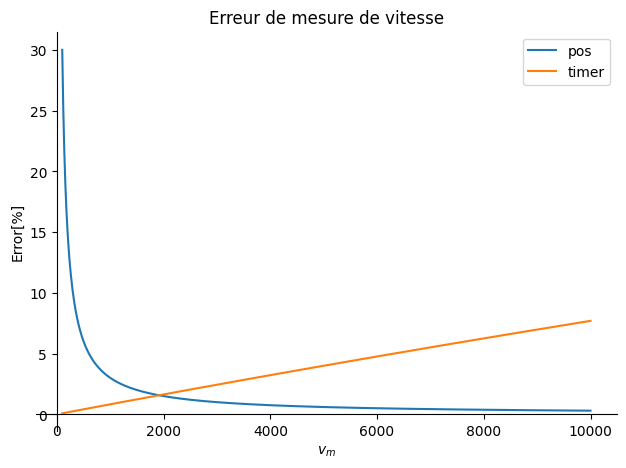

In [40]:
# Définition de quelques valeurs pour faire le tracé
valeurs={R:500, Ts:1e-3, f:1e6}

p=sp.plot(epsilon_vd.subs(valeurs),epsilon_vt.subs(valeurs),(vm,100,10000), title="Erreur de mesure de vitesse", ylabel="Error[%]", legend=True,label=["pos","timer"])

